# Mini-projet — Option B : reconnaître la forme en plus de la trouver

Dans le TP (voir `demo.ipynb`), le réseau trouvait **où** se trouve un cercle rouge dans l'image.
Ici, on va plus loin : l'image peut contenir un **cercle, un carré ou un triangle**, de **n'importe quelle couleur**,
et le réseau doit dire **où** est la figure **et ce que c'est**.

En pratique, on a changé trois choses par rapport au TP :

1. **les données** : le générateur tire au hasard la forme et la couleur ;
2. **le réseau** : il sort 3 valeurs de plus par case de la grille, une par forme ;
3. **la perte** : on ajoute un terme qui pénalise les mauvaises réponses sur la forme.

Tout le reste (grille 8×8, codage de la boîte, IoU, NMS) est repris tel quel du TP.

| fichier | ce qu'il contient |
|---|---|
| `src/dataset_generator_2.py` | le nouveau générateur d'images |
| `src/detector_multiclass.py` | codage des étiquettes, modèle, perte, prédiction |
| `src/train_multiclass.py` | entraînement d'une époque et évaluation |

On suit l'entraînement avec **TensorBoard**, comme dans `demo.ipynb` : courbes, images, graphe du réseau, etc.

> 🇪🇸 **Explicación en español.** Las celdas con 🇪🇸 son explicaciones para entender el notebook a fondo.
> Puedes borrarlas antes de entregar: las celdas en francés son las del informe.
>
> **¿Empiezas desde cero?** Lee primero [guia_desde_cero.md](guia_desde_cero.md): explica píxeles, tensores, neuronas, convolución, ReLU, pérdida, gradiente y TensorBoard con ejemplos numéricos.

### La idea general

El notebook sigue siempre la misma cadena:

```
generador de imágenes ──► codificación de la etiqueta ──► red neuronal ──► pérdida ──► entrenamiento
                                                                                          │
                       comparación ◄── evaluación (IoU, forma) ◄── predicción (decode + NMS)
```

El notebook casi no contiene "inteligencia" propia: **llama a funciones de los scripts de `src/`**.
Esta tabla resume qué función se usa, de dónde viene y qué hace:

| función | archivo | qué hace | dónde se usa |
|---|---|---|---|
| `make_example(size, rng)` | `dataset_generator_2.py` | dibuja una figura al azar (forma + color + posición + tamaño) y devuelve `(imagen, "cx cy w h clase")` | secciones 2 y 6 |
| `code(cx, cy, w, h, clase)` | `detector_multiclass.py` | convierte la etiqueta en el tensor objetivo `(6, 8, 8)` que la red debe aprender a producir | secciones 3 y 6 |
| `MultiClassDetector(deep)` | `detector_multiclass.py` | la red: backbone + cabeza, de `(3, 64, 64)` a `(8, 8, 8)` | secciones 4, 6 y 8 |
| `compute_loss(salida, objetivo)` | `detector_multiclass.py` | mide cuánto se equivoca la red (un solo número) | dentro de `train()` |
| `train(model, loader, optimizer)` | `train_multiclass.py` | una época: para cada lote, predice → pérdida → gradientes → corrige pesos | dentro de `fit()` |
| `evaluate(model, loader, size)` | `train_multiclass.py` | predice cada imagen de validación y calcula IoU, % de formas correctas y matriz de confusión | secciones 6, 7 y 8 |
| `predict(salida, size)` | `detector_multiclass.py` | de la salida de la red a una respuesta final: caja en píxeles + forma | dentro de `evaluate()` y en la sección 7 |
| `decode(salida)` | `detector_multiclass.py` | convierte las 64 celdas en 64 cajas en píxeles + puntuaciones + probabilidades de forma | dentro de `predict()` |
| `iou(a, b)`, `nms(...)` | `detector.py` (TP) | IoU entre cajas; quedarse con la caja de mayor puntuación | dentro de `predict()` / `evaluate()` |
| `Detector()` | `detector.py` (TP) | la red del TP, para comparar | secciones 4 y 8 |
| `plot_history(...)` | `train_multiclass.py` | dibuja las curvas de aprendizaje con matplotlib | sección 6 |
| `show_feature_maps(...)` | `visualize.py` (TP) | dibuja los mapas de características | sección 7 |

**¿Y TensorBoard?** Es una página web que dibuja lo que el entrenamiento va escribiendo en unos archivos de "logs".
En el código, un objeto `SummaryWriter` escribe esos archivos (`add_scalar` para curvas, `add_figure` para imágenes, etc.)
y el programa `tensorboard` los lee y los muestra en http://localhost:6006.

## 1. Mise en place

> 🇪🇸 **Qué pasa en esta sección.**
> 1. Se importan las bibliotecas y nuestras funciones de `src/`. Para que `from src... import` funcione, Python
>    tiene que estar en la carpeta `sujet_tensorboard` (la que contiene `src`): de eso se encarga `os.chdir(...)`.
> 2. Se fijan las constantes: imagen de 64 px, `STRIDE = 8` (cada celda de la cuadrícula cubre 8×8 píxeles),
>    y por tanto `GRID = 8` celdas por lado.
> 3. `torch.manual_seed(0)` hace que lo "aleatorio" sea siempre igual: así, si vuelves a ejecutar, obtienes los mismos números.
> 4. `RUN_DIR` es la carpeta donde TensorBoard guardará todo. Estructura que se crea al ejecutar el notebook:
>    ```
>    tb_runs/option_B/20261026-201655/      <- una carpeta por ejecución del notebook
>        multiclasse_profond/               <- modelo principal (curvas, imágenes, grafo, proyector)
>        detecteur_TP/                      <- detector del TP (sección 8)
>        multiclasse_backbone_TP/           <- modelo con backbone pequeño (sección 8)
>        hparams/                           <- tabla comparativa (sección 8)
>    ```
>    En TensorBoard, cada subcarpeta aparece como un "run" que puedes activar/desactivar a la izquierda.
> 5. `to_tensor` convierte una imagen en tensor. Un **tensor** es simplemente un array de números con varias
>    dimensiones. Una imagen en color de 64×64 es un tensor `(3, 64, 64)`: 3 "capas" (rojo, verde, azul) de 64×64 números.

In [1]:
# ===== Importaciones de bibliotecas estándar de Python =====
import os                       # para cambiar la carpeta de trabajo (os.chdir)
import random                   # números aleatorios de Python (los usa el generador de imágenes)
import sys                      # sys.executable = ruta del Python que ejecuta el notebook (el del entorno rnn)
import tempfile                 # para encontrar la carpeta temporal del sistema (allí irán los logs de TensorBoard)
import time                     # para medir cuánto tarda el entrenamiento
from datetime import datetime   # fecha y hora actuales, para nombrar la carpeta de logs
from pathlib import Path        # rutas de archivos cómodas: Path("a") / "b" -> a\b

# ===== Bibliotecas externas (instaladas con requirements.txt) =====
import numpy as np              # cálculo numérico; aquí solo sirve para pasar de imagen PIL a array
import torch                    # PyTorch: tensores (arrays que pueden calcular gradientes) y redes neuronales
import matplotlib.pyplot as plt # dibujar imágenes y gráficas
from torch.utils.data import DataLoader, TensorDataset  # TensorDataset guarda pares (imagen, objetivo); DataLoader los reparte en lotes
from torch.utils.tensorboard import SummaryWriter       # el objeto que escribe los archivos que lee TensorBoard

# Si el notebook se ejecuta desde la carpeta "notebooks", subimos un nivel (a sujet_tensorboard)
# para que Python encuentre la carpeta "src" al hacer "from src.xxx import ...".
# os.path.abspath("") = carpeta actual; basename = su último nombre; dirname = la carpeta padre.
os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.path.abspath("")) == "notebooks" else ".")

# ===== Nuestras propias piezas (carpeta src/) =====
from src.dataset_generator_2 import make_example, SHAPES  # make_example: crea 1 imagen + etiqueta; SHAPES: nombres de las formas
from src.detector import Detector, STRIDE, iou            # del TP: el detector original, STRIDE = 8 y la función IoU
from src.detector_multiclass import CLASSES, NUM_CLASSES, MultiClassDetector, code, compute_loss, predict  # todo lo nuevo de la opción B
from src.train_multiclass import train, evaluate, plot_history  # entrenar 1 época, calcular métricas, dibujar curvas
from src.visualize import show_feature_maps                # dibujar los mapas de características (del TP)

MODEL_SIZE = 64                  # las imágenes miden 64 x 64 píxeles
GRID = MODEL_SIZE // STRIDE      # tamaño de la cuadrícula: 64 // 8 = 8 (// = división entera)
FIG_DIR = Path("figures")        # carpeta donde se guardan las figuras del informe
FIG_DIR.mkdir(exist_ok=True)     # la crea si no existe (exist_ok=True: no da error si ya existe)
torch.manual_seed(0)             # semilla de PyTorch: los números "aleatorios" serán siempre los mismos (resultados reproducibles)

# Carpeta de logs de TensorBoard: <temporal>/tb_runs/option_B/<fecha-hora>
# (en la carpeta temporal y no en el proyecto porque TensorBoard funciona mal en carpetas sincronizadas tipo ownCloud).
# Cada ejecución del notebook crea una carpeta nueva y dentro cada modelo tendrá su subcarpeta.
RUN_DIR = Path(tempfile.gettempdir()) / "tb_runs" / "option_B" / datetime.now().strftime("%Y%m%d-%H%M%S")  # strftime da un texto tipo 20261026-201655
print("Logs TensorBoard :", RUN_DIR)  # muestra dónde se guardarán los logs
print("Classes :", CLASSES)           # ('circle', 'square', 'triangle') -> clases 0, 1, 2

Matplotlib is building the font cache; this may take a moment.


Logs TensorBoard : C:\Users\lucas\AppData\Local\Temp\tb_runs\option_B\20261026-201655
Classes : ('circle', 'square', 'triangle')


In [2]:
# Imprime el comando que hay que copiar en una terminal PowerShell para abrir TensorBoard.
# Se puede lanzar ya: TensorBoard relee los logs cada pocos segundos, así que las curvas
# aparecen mientras el modelo entrena (basta con refrescar la página del navegador).
print(f'& "{sys.executable}" -m tensorboard.main --logdir "{RUN_DIR.parent}" --port 6006')  # f-string: {x} se sustituye por el valor de x; RUN_DIR.parent = carpeta con TODAS las ejecuciones
print("Puis ouvrir http://localhost:6006")  # dirección web donde TensorBoard muestra sus pestañas

& "C:\Users\lucas\Downloads\ISIS\NNR\rnn\Scripts\python.exe" -m tensorboard.main --logdir "C:\Users\lucas\AppData\Local\Temp\tb_runs\option_B" --port 6006
Puis ouvrir http://localhost:6006


In [3]:
def to_tensor(image):  # convierte una imagen PIL en un tensor que la red pueda leer
    # image.convert("RGB"): asegura 3 canales (rojo, verde, azul)
    # np.asarray(..., dtype=np.float32): imagen -> array de forma (alto=64, ancho=64, canales=3) con números decimales 0..255
    # .copy(): copia escribible (torch.from_numpy avisa si el array es de solo lectura)
    array = np.asarray(image.convert("RGB"), dtype=np.float32).copy()
    # torch.from_numpy: array numpy -> tensor de PyTorch
    # .permute(2, 0, 1): reordena los ejes (64, 64, 3) -> (3, 64, 64), el formato "canales primero" que exige nn.Conv2d
    # / 255.0: pasa los valores de 0..255 a 0..1 (las redes aprenden mejor con valores pequeños)
    return torch.from_numpy(array).permute(2, 0, 1) / 255.0

## 2. Les nouvelles images

Le générateur fonctionne comme celui du TP, sauf que :
* la **forme** est tirée au hasard : cercle (classe 0), carré (1) ou triangle (2) ;
* la **couleur** est tirée au hasard parmi 5 couleurs, **indépendamment de la forme**.
  Le réseau ne peut donc pas tricher en regardant la couleur : il est obligé d'apprendre la forme ;
* l'étiquette gagne un 5ᵉ nombre, le numéro de la classe : `cx cy w h classe`.

> 🇪🇸 **Cómo funciona `make_example` (en `src/dataset_generator_2.py`).**
> 1. Crea una imagen gris clara de 64×64 (el gris varía un poco de una imagen a otra).
> 2. Elige la clase al azar: `class_id = rng.randrange(3)` → 0, 1 o 2, y la forma es `SHAPES[class_id]`.
> 3. Elige un color al azar entre 5, **sin relación con la forma**. Si los círculos fueran siempre rojos,
>    la red podría "hacer trampa" mirando solo el color; así está obligada a mirar el contorno.
> 4. Elige el lado (`side`) entre 10 y 21 px y la esquina superior izquierda `(x1, y1)` de modo que la figura quede dentro.
> 5. Dibuja la figura con PIL y devuelve la etiqueta `"cx cy w h clase"`: centro, ancho, alto (en píxeles) y número de clase.
>
> Por ejemplo `25.0 14.0 16 16 1` significa: un **cuadrado** (clase 1) de 16×16 px centrado en el píxel (25, 14).
>
> Al final de la celda creamos el `writer` (el "diario" de TensorBoard) y guardamos la figura en él con `add_figure`:
> la verás en la pestaña **IMAGES** de TensorBoard.

25.0 14.0 16 16 1
30.0 30.0 18 18 1
42.5 28.5 15 15 0


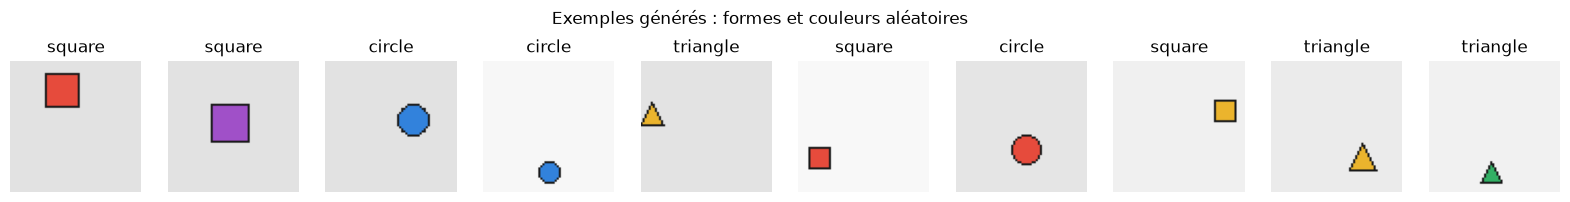

In [4]:
rng = random.Random(123)                                        # generador aleatorio propio con semilla 123: siempre las mismas 10 imágenes
examples = [make_example(MODEL_SIZE, rng) for _ in range(10)]   # llama 10 veces a make_example (dataset_generator_2.py) -> lista de 10 pares (imagen PIL, etiqueta en texto)
for image, label in examples[:3]:                                # [:3] = los 3 primeros elementos
    print(label)                                                 # la etiqueta en bruto: "cx cy w h clase"

fig, axes = plt.subplots(1, 10, figsize=(20, 2.4))               # figura con 1 fila y 10 sub-gráficas ("axes"); figsize = tamaño en pulgadas
for ax, (image, label) in zip(axes, examples):                   # zip empareja cada sub-gráfica con un ejemplo
    ax.imshow(image)                                             # dibuja la imagen
    ax.set_title(SHAPES[int(label.split()[-1])])                 # label.split() -> 5 trozos de texto; [-1] = el último = número de clase; SHAPES[...] = nombre de la forma
    ax.axis("off")                                               # oculta los ejes con números
fig.suptitle("Exemples générés : formes et couleurs aléatoires") # título general de la figura
fig.savefig(FIG_DIR / "exemples_dataset.png", dpi=120, bbox_inches="tight")  # guarda la figura para el informe (dpi = resolución, bbox_inches="tight" recorta los márgenes)

# Creamos el "diario" de TensorBoard del modelo principal: todo lo que escribamos con 'writer'
# irá a la carpeta RUN_DIR/multiclasse_profond, que TensorBoard mostrará como un "run" llamado así.
writer = SummaryWriter(log_dir=str(RUN_DIR / "multiclasse_profond"))  # str(): SummaryWriter quiere la ruta como texto
writer.add_figure("Donnees/exemples", fig, close=False)  # guarda la figura en la pestaña IMAGES ("Donnees/" = grupo); close=False para poder mostrarla después
plt.show()                                               # muestra la figura aquí en el notebook

## 3. Ce que le réseau doit apprendre (codage des étiquettes)

Rappel du TP : l'image est découpée en une grille de 8×8 cases. La case qui contient le centre de la figure
est « responsable » de la figure, et c'est elle qui doit donner la boîte.

Pour l'option B, on ajoute simplement **le numéro de la forme** dans cette case.
La cible passe donc de 5 à 6 valeurs par case : `(objet ?, dx, dy, largeur, hauteur, classe)`.
Les autres cases restent à 0 : il n'y a rien à y prédire.

De son côté, le réseau donne 8 valeurs par case : les 5 du TP + **un score par forme**.
On transforme ces 3 scores en probabilités (avec un *softmax*, elles sont positives et font 100 % au total),
et la forme prédite est celle qui a la plus grande probabilité.

> 🇪🇸 **La codificación, paso a paso con el ejemplo que sale abajo** (`25.0 14.0 16 16 1`).
>
> La red no da una sola caja: da una predicción **por cada una de las 64 celdas** de la cuadrícula 8×8.
> Hay que decirle qué debe responder cada celda. Eso hace `code()`:
>
> 1. Centro en "unidades de celda": `gx = 25 / 64 × 8 = 3.125` y `gy = 14 / 64 × 8 = 1.75`.
> 2. La celda responsable es la parte entera: **columna 3, fila 1**.
> 3. La posición dentro de la celda es la parte decimal: `dx = 0.125` (muy a la izquierda de la celda), `dy = 0.75` (abajo).
> 4. El tamaño se expresa como fracción de la imagen: `w = h = 16 / 64 = 0.25`.
> 5. En la celda (1, 3) se escribe `[1, 0.125, 0.75, 0.25, 0.25, 1]` → "hay objeto, aquí, de este tamaño, y es un cuadrado".
>    Las otras 63 celdas quedan a 0 → "aquí no hay nada".
>
> ¿Por qué valores entre 0 y 1? Porque la red los produce pasando su salida por una **sigmoide**,
> una función que transforma cualquier número en uno entre 0 y 1 (σ(0) = 0.5, σ(5) ≈ 0.99, σ(−5) ≈ 0.01).
>
> **Decodificación (`decode()`, el camino inverso):** `cx = (columna + dx) × 8 = (3 + 0.125) × 8 = 25` ✔,
> `w = 0.25 × 64 = 16` ✔. Después se pasa de (centro, tamaño) a esquinas: `x1 = cx − w/2`, `x2 = cx + w/2`, etc.
>
> **La forma:** la red da 3 números ("logits") por celda, uno por forma, por ejemplo `[2.0, 0.1, −1.0]`.
> El **softmax** los convierte en probabilidades que suman 1: `e^2 / (e^2 + e^0.1 + e^−1) ≈ 0.83` para el círculo,
> 0.12 para el cuadrado, 0.04 para el triángulo → la red responde "círculo, al 83 %".

In [5]:
image, label = examples[0]                                    # primer ejemplo generado arriba
cx, cy, w, h, class_id = map(float, label.split())            # parte el texto en 5 trozos y convierte cada uno a número decimal
target = code(cx, cy, w, h, int(class_id), size=MODEL_SIZE)   # code() de detector_multiclass.py: etiqueta -> tensor objetivo de forma (6, 8, 8)
row, col = divmod(int(target[0].argmax()), GRID)              # target[0] = mapa 8x8 de "¿objeto?"; argmax = posición del 1 como índice plano 0..63; divmod(i, 8) = (fila, columna)
print("forme   :", CLASSES[int(class_id)])                    # nombre de la forma
print("case    :", (row, col))                                # celda responsable (fila, columna)
print("cible   : objet, dx, dy, w, h, classe =", [round(v, 3) for v in target[:, row, col].tolist()])  # target[:, row, col] = los 6 valores de esa celda; tolist() -> lista Python; round(v, 3) -> 3 decimales
print("nombre de cases avec un objet :", int(target[0].sum()))  # suma del mapa "¿objeto?" = número de celdas positivas (debe ser 1)

forme   : square
case    : (1, 3)
cible   : objet, dx, dy, w, h, classe = [1.0, 0.125, 0.75, 0.25, 0.25, 1.0]
nombre de cases avec un objet : 1


## 4. Le réseau

* **La tête** sort 8 canaux au lieu de 5 (5 + 3 formes).
* **Le backbone** garde les règles du TP (sortie 32×8×8, BatchNorm + ReLU à chaque couche),
  mais on a ajouté une deuxième convolution à chaque étage. Reconnaître une forme de n'importe quelle couleur
  et bien placer la boîte est plus dur que de trouver un cercle rouge : un réseau un peu plus profond
  « voit » une zone plus large de l'image et a plus de capacité.
  Avec `deep=False` on retrouve exactement le backbone du TP (utile pour comparer à la section 8).

> 🇪🇸 **Cómo está hecha la red (`MultiClassDetector` en `src/detector_multiclass.py`).**
>
> Cada "bloque" (`conv_block`) es: **convolución 3×3 → BatchNorm → ReLU**.
> * La **convolución 3×3** desliza un pequeño filtro de 3×3 píxeles por la imagen y calcula, en cada posición,
>   una suma ponderada: así detecta patrones locales (bordes, esquinas, manchas de color). Con `stride=2`
>   el filtro avanza de 2 en 2 píxeles, así que la salida mide la mitad.
> * La **BatchNorm** recentra y reescala los valores para que el entrenamiento sea más estable.
> * La **ReLU** pone a 0 los valores negativos (`max(0, x)`): es la "no linealidad" que permite aprender cosas complejas.
>
> Tamaños con `deep=True` (lo que imprime la celda de abajo):
> ```
> imagen          3 × 64 × 64
> bloque s=2  →  16 × 32 × 32     bloque s=1 → 16 × 32 × 32
> bloque s=2  →  32 × 16 × 16     bloque s=1 → 32 × 16 × 16
> bloque s=2  →  32 ×  8 ×  8     bloque s=1 → 32 ×  8 ×  8   <- "feature maps": 32 números por celda
> cabeza 1×1  →   8 ×  8 ×  8     <- 8 números por celda: objeto?, dx, dy, w, h, círculo, cuadrado, triángulo
> ```
> La **cabeza** es una convolución 1×1: para cada celda, toma sus 32 números y calcula 8 combinaciones lineales de ellos.
> Es como una pequeña capa "densa" aplicada a cada celda por separado.
>
> Los bloques con `stride=1` (los "extra" respecto al TP) no cambian el tamaño, pero cada celda final "ve" una zona
> más grande de la imagen y la red tiene más pesos: 35 736 en lugar de 6 309.

In [6]:
model = MultiClassDetector()                                  # crea la red de detector_multiclass.py (deep=True por defecto) con pesos aleatorios
print(model)                                                  # lista todas las capas
dummy = torch.zeros(2, 3, MODEL_SIZE, MODEL_SIZE)             # lote falso: 2 imágenes negras de 3x64x64, solo para comprobar los tamaños
print("feature maps :", tuple(model.feature_maps(dummy).shape))  # solo el backbone -> (2, 32, 8, 8)
print("sortie       :", tuple(model(dummy).shape))               # model(x) llama a forward: backbone + cabeza -> (2, 8, 8, 8)
n_params = sum(p.numel() for p in model.parameters())         # parameters() recorre todos los tensores de pesos; numel() = cuántos números tiene cada uno; sum = total
n_params_tp = sum(p.numel() for p in Detector().parameters()) # lo mismo para el detector del TP (detector.py), para comparar
print(f"paramètres : {n_params} (modèle du TP : {n_params_tp})")  # muestra los dos totales

MultiClassDetector(
  (backbone): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Conv2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (13): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): Re

## 5. La fonction de perte

On garde les deux termes du TP et on en ajoute un troisième :

$$
\mathcal L = \underbrace{\text{BCE}(\text{objet})}_{\text{toutes les cases}}
 + 10 \times \underbrace{\text{MSE}(\text{boîte})}_{\text{case de l'objet}}
 + 1 \times \underbrace{\text{CE}(\text{classe})}_{\text{case de l'objet}}
$$

* **BCE** (comme au TP) : « y a-t-il un objet dans cette case ? ». On donne 10 fois plus de poids à la case
  qui contient l'objet, sinon les 63 cases vides l'emporteraient et le réseau répondrait toujours « non ».
* **MSE** (comme au TP) : l'écart entre la boîte prédite et la vraie boîte.
* **CE** (nouveau) : l'entropie croisée, qui vaut $-\log(\text{probabilité donnée à la bonne forme})$.
  Elle est nulle si le réseau est sûr à 100 % de la bonne réponse, et grandit quand il se trompe.
  On ne la calcule que sur la case de l'objet : ailleurs il n'y a pas de forme à reconnaître.

> 🇪🇸 **La pérdida (`compute_loss` en `src/detector_multiclass.py`), término por término.**
>
> La pérdida es un número que dice "cuánto se equivoca la red". Entrenar = cambiar los pesos para que baje.
>
> 1. **¿Hay objeto?** – entropía cruzada binaria (BCE) sobre las 64 celdas. Para una celda, si la red da probabilidad `p`:
>    vale `−log(p)` si debía haber objeto, `−log(1 − p)` si no. Ejemplo: `p = 0.9` donde hay objeto → 0.105 (bien);
>    `p = 0.1` → 2.3 (mal). Como solo 1 celda de 64 tiene objeto, una red perezosa respondería siempre "no";
>    por eso el error en la celda con objeto se multiplica por 10 (`pos_weight=10`).
> 2. **¿Dónde y de qué tamaño?** – error cuadrático medio (MSE) entre `(dx, dy, w, h)` predichos y reales,
>    **solo en la celda con objeto**. Se multiplica por 10 porque, al ser valores entre 0 y 1, sus errores al cuadrado son muy pequeños.
> 3. **¿Qué forma?** (lo nuevo) – entropía cruzada (`cross_entropy`) = `−log(probabilidad dada a la forma correcta)`.
>    Si la red da 0.9 a la forma correcta → 0.105; si da 1/3 (al azar) → 1.10; si da 0.01 → 4.6.
>    `cross_entropy` de PyTorch aplica el softmax por dentro, por eso se le pasan los logits "en bruto".
>
> Abajo se calcula la pérdida de la red **sin entrenar**: sale alrededor de 3.4, la suma de tres términos "malos"
> (red que no sabe ni dónde está el objeto, ni su tamaño, ni su forma). Tras el entrenamiento baja a ≈ 0.002.

In [7]:
images_demo = torch.stack([to_tensor(im) for im, _ in examples])      # convierte las 10 imágenes y las apila en un solo tensor (10, 3, 64, 64); "_" = la etiqueta, que aquí no usamos
targets_demo = torch.stack([code(*map(float, lb.split()[:4]), int(lb.split()[4]), size=MODEL_SIZE)  # para cada etiqueta: los 4 primeros números (cx, cy, w, h) en float + la clase en int -> code(); "*" pasa los 4 valores como 4 argumentos
                            for _, lb in examples])                    # ... para los 10 ejemplos, y se apilan -> (10, 6, 8, 8)
with torch.no_grad():                                                  # sin calcular gradientes: solo queremos ver un número, no entrenar
    print("perte d'un réseau pas encore entraîné :", compute_loss(model(images_demo), targets_demo).item())  # compute_loss() de detector_multiclass.py; .item() = tensor de 1 valor -> número Python
# Para comparar: responder al azar entre 3 formas da una entropía cruzada CE = log(3) ≈ 1.10

perte d'un réseau pas encore entraîné : 3.4235734939575195


## 6. Entraînement

* 3 000 images pour apprendre, 600 autres pour vérifier (jamais vues pendant l'apprentissage).
* Adam, pas d'apprentissage 0,003, paquets de 64 images, 40 époques ; le pas est divisé par 10
  aux trois quarts pour affiner la fin.

À chaque époque, la fonction `fit` écrit dans TensorBoard :
* les courbes (**SCALARS**) : perte, IoU moyen, % d'IoU > 0,5, % de bonnes formes, pas d'apprentissage ;
* la répartition des poids de chaque couche (**HISTOGRAMS** / **DISTRIBUTIONS**) ;
* et une seule fois, au début, le schéma du réseau (**GRAPHS**).

> 🇪🇸 **Cómo se entrena.**
>
> * `make_dataset` genera las imágenes **en memoria** (no escribe archivos) y las convierte en tensores con `to_tensor` y `code`.
> * El `DataLoader` reparte las 3000 imágenes en **lotes** (batches) de 64. La red procesa 64 imágenes a la vez
>   y corrige sus pesos una vez por lote → unas 47 correcciones por época.
> * Una **época** = pasar una vez por las 3000 imágenes. Hacemos 40.
>
> Lo que hace `train()` (en `src/train_multiclass.py`) para cada lote:
> ```
> optimizer.zero_grad()                         # 1. borra los gradientes del lote anterior
> loss = compute_loss(model(images), targets)   # 2. predice y mide el error
> loss.backward()                               # 3. calcula, para cada peso, en qué dirección hay que moverlo para bajar el error (gradiente)
> optimizer.step()                              # 4. mueve cada peso un poquito en esa dirección (Adam)
> ```
> El tamaño de ese "poquito" es el **paso de aprendizaje** (`lr = 0.003`). El `StepLR` lo divide por 10 en la
> época 30: al principio se avanza rápido y al final se hacen ajustes finos.
>
> `model.train()` / `model.eval()`: la BatchNorm se comporta distinto al entrenar (usa la media del lote)
> y al evaluar (usa la media aprendida). `train()` y `evaluate()` llaman al modo correcto ellos mismos.
>
> **Lo que `fit()` escribe en TensorBoard en cada época:**
> * `add_scalar` → un punto en una curva (**SCALARS**): pérdida, IoU, % de formas correctas, `lr`.
> * `add_histogram` → la distribución de los pesos de cada capa (**HISTOGRAMS / DISTRIBUTIONS**): si los pesos dejan de moverse, la red ya no aprende.
> * `add_graph` (solo al principio) → el esquema de la red (**GRAPHS**): haz doble clic en los bloques para abrirlos.
>
> En nuestra ejecución: época 1 → IoU 0.63 y 96 % de formas correctas; época 40 → IoU 0.95 y 100 %.
> La forma se aprende casi de inmediato; la precisión de la caja mejora poco a poco (y mejora otra vez después de la época 30, cuando baja el `lr`).

In [8]:
def make_dataset(count, seed):                        # genera 'count' ejemplos en memoria (sin archivos) y los devuelve listos para PyTorch
    rng = random.Random(seed)                         # misma semilla -> mismas imágenes en cada ejecución
    images, targets = [], []                          # dos listas vacías que vamos llenando
    for _ in range(count):                            # repetir 'count' veces ("_" porque no usamos el número de vuelta)
        image, label = make_example(MODEL_SIZE, rng)  # nueva imagen + etiqueta "cx cy w h clase" (dataset_generator_2.py)
        cx, cy, w, h, class_id = label.split()        # 5 trozos de texto
        images.append(to_tensor(image))               # imagen -> tensor (3, 64, 64)
        targets.append(code(float(cx), float(cy), float(w), float(h), int(class_id), size=MODEL_SIZE))  # etiqueta -> objetivo (6, 8, 8)
    return TensorDataset(torch.stack(images), torch.stack(targets))  # stack -> (count, 3, 64, 64) y (count, 6, 8, 8); TensorDataset permite pedir dataset[i] = (imagen_i, objetivo_i)

train_set = make_dataset(3000, seed=7)                # 3000 ejemplos para aprender
val_set = make_dataset(600, seed=8)                   # otra semilla -> 600 imágenes distintas, solo para evaluar
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)  # reparte en lotes de 64 imágenes; shuffle=True = orden distinto en cada época
val_loader = DataLoader(val_set, batch_size=64)       # para evaluar no hace falta mezclar (y así el orden coincide con val_set)
print(len(train_set), "images d'entraînement,", len(val_set), "images de validation")  # len() = número de ejemplos

3000 images d'entraînement, 600 images de validation


In [9]:
def fit(model, epochs, writer, lr=3e-3, verbose=True):  # entrena 'model' 'epochs' épocas escribiendo en 'writer'; lr = paso de aprendizaje (3e-3 = 0.003); verbose = imprimir o no
    # Entrena el modelo, lo registra todo en TensorBoard y devuelve el historial de métricas
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam: el algoritmo que corrige los pesos a partir de los gradientes; recibe la lista de pesos que puede modificar
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=int(epochs * 0.75), gamma=0.1)  # cada step_size épocas (30 de 40) multiplica lr por gamma: 0.003 -> 0.0003 para afinar al final
    model.eval()                                                   # modo evaluación antes de dibujar el grafo: así la BatchNorm no cambia sus estadísticas
    writer.add_graph(model, next(iter(train_loader))[0][:2])       # iter/next = primer lote del loader; [0] = las imágenes; [:2] = 2 imágenes. TensorBoard las pasa por la red para dibujar su esquema (pestaña GRAPHS)
    history = {k: [] for k in ("loss", "mean_iou", "iou_gt_05", "accuracy", "detection_ok")}  # diccionario: una lista vacía por métrica, se añadirá un valor por época
    for epoch in range(1, epochs + 1):                             # épocas 1, 2, ..., epochs (1 época = ver las 3000 imágenes una vez)
        history["loss"].append(train(model, train_loader, optimizer))  # train() de train_multiclass.py: hace una época completa y devuelve la pérdida media
        writer.add_scalar("Apprentissage/pas", optimizer.param_groups[0]["lr"], epoch)  # registra el lr actual (Adam lo guarda en param_groups[0]["lr"])
        scheduler.step()                                           # avisa al scheduler de que acabó una época (baja el lr cuando toca)
        metrics = evaluate(model, val_loader, MODEL_SIZE)          # evaluate() de train_multiclass.py: métricas sobre las 600 imágenes de validación
        for key in ("mean_iou", "iou_gt_05", "accuracy", "detection_ok"):  # para cada métrica...
            history[key].append(metrics[key])                      # ...guarda su valor de esta época
        # Pestaña SCALARS: add_scalar(nombre, valor, x) añade un punto a la curva "nombre" en la abscisa x
        writer.add_scalar("Loss/train", history["loss"][-1], epoch)  # [-1] = último valor añadido (el de esta época)
        writer.add_scalar("Validation/IoU_moyen", metrics["mean_iou"], epoch)          # IoU medio
        writer.add_scalar("Validation/IoU_gt_0.5", metrics["iou_gt_05"], epoch)        # % de imágenes con IoU > 0.5
        writer.add_scalar("Validation/precision_classe", metrics["accuracy"], epoch)   # % de formas acertadas
        writer.add_scalar("Validation/detection_ok", metrics["detection_ok"], epoch)   # % con buena caja Y buena forma
        # Pestañas HISTOGRAMS / DISTRIBUTIONS: cómo se reparten los pesos de cada capa en esta época
        for name, param in model.named_parameters():               # recorre cada tensor de pesos con su nombre (ej. "backbone.0.weight")
            writer.add_histogram(f"Poids/{name}", param, epoch)    # guarda su histograma
        if verbose and (epoch % 5 == 0 or epoch == 1):             # imprime solo en la época 1 y en las múltiplos de 5 (% = resto de la división)
            print(f"époque {epoch:2d}  perte {history['loss'][-1]:.3f}  IoU {metrics['mean_iou']:.3f}  "  # :2d = entero en 2 caracteres; :.3f = 3 decimales
                  f"IoU>0.5 {metrics['iou_gt_05']:.0%}  forme {metrics['accuracy']:.0%}")              # :.0% = porcentaje sin decimales
    writer.flush()                                                 # fuerza a escribir en disco todo lo pendiente
    return history                                                 # devuelve las curvas para dibujarlas con matplotlib

EPOCHS = 40                              # número de épocas
torch.manual_seed(0)                     # misma semilla -> mismos pesos iniciales en cada ejecución
model = MultiClassDetector(deep=True)    # red nueva sin entrenar (sustituye a la de la sección 4)
start = time.time()                      # hora de inicio, en segundos
history = fit(model, EPOCHS, writer)     # ¡el entrenamiento!
print(f"durée : {time.time() - start:.0f} s")  # tiempo transcurrido (:.0f = sin decimales)

C:\Users\lucas\Downloads\ISIS\NNR\rnn\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\lucas\Downloads\ISIS\NNR\rnn\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


époque  1  perte 1.005  IoU 0.626  IoU>0.5 79%  forme 96%


époque  5  perte 0.032  IoU 0.876  IoU>0.5 100%  forme 100%


époque 10  perte 0.014  IoU 0.904  IoU>0.5 100%  forme 100%


époque 15  perte 0.009  IoU 0.889  IoU>0.5 100%  forme 100%


époque 20  perte 0.006  IoU 0.905  IoU>0.5 100%  forme 100%


époque 25  perte 0.005  IoU 0.924  IoU>0.5 100%  forme 100%


époque 30  perte 0.004  IoU 0.926  IoU>0.5 100%  forme 100%


époque 35  perte 0.002  IoU 0.948  IoU>0.5 100%  forme 100%


époque 40  perte 0.002  IoU 0.948  IoU>0.5 100%  forme 100%
durée : 192 s


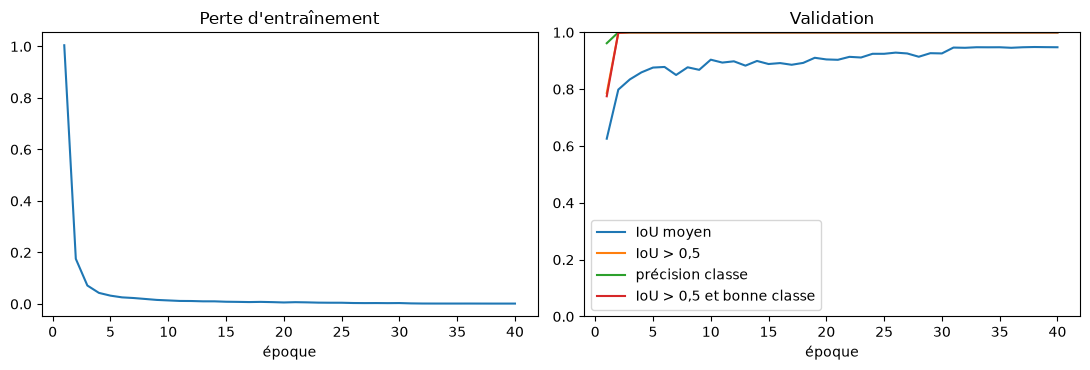

In [10]:
# Las mismas curvas que se ven en directo en TensorBoard, pero como imagen para el informe
plot_history(history, FIG_DIR / "courbes_apprentissage.png")   # plot_history() de train_multiclass.py: pérdida (izquierda) y métricas de validación (derecha), y guarda el PNG

## 7. Évaluation

On mesure deux choses séparément, puis les deux ensemble :
* **Trouver la figure** : l'IoU (recouvrement entre la boîte prédite et la vraie, de 0 à 1)
  et le pourcentage d'images où il dépasse 0,5.
* **Reconnaître la forme** : le pourcentage de bonnes réponses, et la **matrice de confusion**
  (ligne = vraie forme, colonne = forme prédite ; tout doit être sur la diagonale).
* **Les deux à la fois** : bonne boîte (IoU > 0,5) **et** bonne forme.

> 🇪🇸 **Cómo se evalúa (`evaluate` en `src/train_multiclass.py`).** Para cada imagen de validación:
> 1. `predict()` toma la salida de la red `(8, 8, 8)` y llama a `decode()` → 64 cajas en píxeles, 64 puntuaciones
>    "¿objeto?" y 64 trios de probabilidades de forma. `nms()` ordena por puntuación y nos quedamos con la primera:
>    **la celda más segura de tener el objeto**. La forma predicha es la de mayor probabilidad **en esa celda**.
> 2. `target_to_label()` reconstruye la caja y la forma reales a partir del objetivo.
> 3. Se calcula el **IoU** (función `iou` del TP) = área de la intersección / área de la unión de las dos cajas.
>    Ejemplo: dos cajas de 10×10 desplazadas 5 px en horizontal → intersección 5×10 = 50, unión 100 + 100 − 50 = 150 → IoU = 0.33.
>    IoU = 1 → cajas idénticas; IoU = 0 → no se tocan. Se considera "buena detección" si IoU > 0.5.
>
> **Matriz de confusión:** `confusion[real, predicha]` cuenta las imágenes. Si la red es perfecta, todo está en la diagonal.
> * **Precisión** de una forma = de las veces que la red dijo "cuadrado", ¿cuántas era de verdad un cuadrado? (por columnas)
> * **Recall** (exhaustividad) = de los cuadrados reales, ¿cuántos reconoció? (por filas)
>
> Aquí todo sale al 100 %: las formas son fáciles de distinguir (fondo liso, bordes nítidos).

In [11]:
metrics = evaluate(model, val_loader, MODEL_SIZE)                 # evaluación final del modelo entrenado -> diccionario de métricas
print(f"IoU moyen                 : {metrics['mean_iou']:.3f}")   # IoU medio (3 decimales)
print(f"IoU > 0,5                 : {metrics['iou_gt_05']:.1%}")  # :.1% = porcentaje con 1 decimal
print(f"bonne forme               : {metrics['accuracy']:.1%}")   # % de formas acertadas
print(f"IoU > 0,5 et bonne forme  : {metrics['detection_ok']:.1%}")  # % con las dos cosas bien
for name, value in zip(CLASSES, metrics["iou_per_class"]):       # zip empareja cada nombre de forma con su IoU medio
    print(f"  IoU moyen ({name:8s}) : {value:.3f}")               # :8s = texto en 8 caracteres (alinea la columna)

confusion = metrics["confusion"]                                  # matriz 3x3: confusion[forma real, forma predicha] = número de imágenes
recall = confusion.diag() / confusion.sum(dim=1)                  # diag() = aciertos de cada forma; sum(dim=1) = suma de cada FILA = total de figuras reales de esa forma
precision = confusion.diag() / confusion.sum(dim=0).clamp(min=1)  # sum(dim=0) = suma de cada COLUMNA = veces que se predijo esa forma; clamp(min=1) evita dividir por 0
for k, name in enumerate(CLASSES):                                # enumerate da (índice, nombre): (0, "circle"), (1, "square")...
    print(f"  {name:8s} précision {precision[k]:.1%}  rappel {recall[k]:.1%}")  # precisión y recall de cada forma

# Pestaña HISTOGRAMS de TensorBoard: cómo se reparten los 600 IoU de validación
writer.add_histogram("Validation/IoU_par_image", metrics["ious"], EPOCHS)  # se registra en el paso 40 (la última época)

IoU moyen                 : 0.948
IoU > 0,5                 : 100.0%
bonne forme               : 100.0%
IoU > 0,5 et bonne forme  : 100.0%
  IoU moyen (circle  ) : 0.948
  IoU moyen (square  ) : 0.948
  IoU moyen (triangle) : 0.946
  circle   précision 100.0%  rappel 100.0%
  square   précision 100.0%  rappel 100.0%
  triangle précision 100.0%  rappel 100.0%


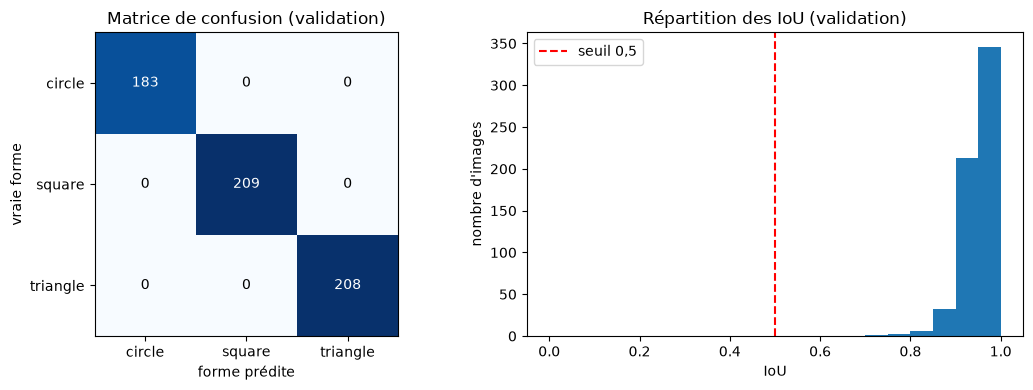

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))                   # figura con 2 gráficas lado a lado
# --- Izquierda: matriz de confusión ---
axes[0].imshow(confusion, cmap="Blues")                           # dibuja la matriz como imagen: cuanto mayor el número, más azul
for i in range(NUM_CLASSES):                                      # para cada fila (forma real)...
    for j in range(NUM_CLASSES):                                  # ...y cada columna (forma predicha)
        dark = confusion[i, j] > confusion.max() / 2               # ¿casilla oscura? (más de la mitad del máximo)
        axes[0].text(j, i, int(confusion[i, j]), ha="center", va="center", color="white" if dark else "black")  # escribe el número en el centro de la casilla; blanco sobre oscuro para que se lea
axes[0].set_xticks(range(NUM_CLASSES), CLASSES)                   # nombres de las formas en el eje x
axes[0].set_yticks(range(NUM_CLASSES), CLASSES)                   # y en el eje y
axes[0].set_xlabel("forme prédite")                               # eje x = lo que dijo la red
axes[0].set_ylabel("vraie forme")                                 # eje y = la respuesta correcta
axes[0].set_title("Matrice de confusion (validation)")            # título
# --- Derecha: histograma de los IoU ---
axes[1].hist(metrics["ious"].numpy(), bins=20, range=(0, 1))      # cuenta cuántas imágenes caen en cada uno de 20 intervalos entre 0 y 1 (.numpy(): matplotlib prefiere arrays numpy)
axes[1].axvline(0.5, color="red", linestyle="--", label="seuil 0,5")  # línea vertical roja discontinua en IoU = 0.5
axes[1].set_xlabel("IoU")                                         # eje x
axes[1].set_ylabel("nombre d'images")                             # eje y
axes[1].set_title("Répartition des IoU (validation)")             # título
axes[1].legend()                                                  # muestra la leyenda ("seuil 0,5")
fig.tight_layout()                                                # ajusta los espacios para que nada se superponga
fig.savefig(FIG_DIR / "confusion_iou.png", dpi=150)               # guarda para el informe
writer.add_figure("Evaluation/confusion_et_iou", fig, close=False)  # y la envía a TensorBoard (pestaña IMAGES)
plt.show()                                                        # la muestra aquí

**Et selon la taille de la figure ?** Le côté des figures va de 10 à 21 pixels.
On coupe la validation en trois groupes pour voir si les petites figures posent plus de problèmes.

> 🇪🇸 **Por tamaño.** Se lee el ancho de cada figura en su objetivo (canal 3 de la celda con objeto, × 64 → píxeles)
> y se separan las 600 imágenes en tres grupos. `metrics['ious']` está en el mismo orden que `val_set`
> porque `val_loader` no mezcla, por eso se puede filtrar con la misma máscara `group`.
> En nuestra ejecución: IoU 0.928 para las pequeñas (10–13 px) frente a 0.962 para las grandes (18–21 px).
> Es lógico: en una figura pequeña, un error de 1 píxel pesa mucho más en proporción.

In [13]:
sides = []                                                         # lado (en píxeles) de cada figura de validación
for target in val_set.tensors[1]:                                  # val_set.tensors = (imágenes, objetivos); [1] = los 600 objetivos (6, 8, 8)
    flat = target.reshape(6, -1)                                   # (6, 8, 8) -> (6, 64): cada columna es una celda; -1 = "calcula tú este tamaño"
    sides.append(float(flat[3, flat[0].argmax()]) * MODEL_SIZE)    # flat[0].argmax() = celda con objeto; flat[3, ...] = su ancho relativo w; * 64 -> píxeles
sides = torch.tensor(sides)                                        # lista -> tensor, para poder comparar las 600 de golpe
model.eval()                                                       # modo evaluación
with torch.no_grad():                                              # sin gradientes
    val_logits = model(val_set.tensors[0])                         # pasa las 600 imágenes de una vez -> (600, 8, 8, 8)
pred_cls = torch.tensor([predict(l, MODEL_SIZE)[2] for l in val_logits])  # predict() devuelve (caja, score, clase, prob); [2] = clase predicha
true_cls = torch.tensor([int(t[5].flatten()[t[0].flatten().argmax()]) for t in val_set.tensors[1]])  # canal 5 (clase) leído en la celda con objeto = clase real
for low, high in ((10, 13), (14, 17), (18, 21)):                   # tres grupos de tamaño (en píxeles)
    group = (sides >= low) & (sides <= high)                       # máscara True/False: True para las figuras de este grupo (& = "y")
    print(f"côté {low:2d}-{high:2d} px : {int(group.sum()):3d} images  "   # group.sum() = número de True = imágenes del grupo
          f"IoU moyen {metrics['ious'][group].mean():.3f}  "                # metrics['ious'][group] = IoU solo de esas imágenes (mismo orden que val_set porque val_loader no mezcla)
          f"IoU>0.5 {(metrics['ious'][group] > 0.5).float().mean():.1%}  "  # (x > 0.5).float() da 1 o 0; la media = proporción
          f"forme {(pred_cls[group] == true_cls[group]).float().mean():.1%}")  # proporción de formas acertadas en el grupo

côté 10-13 px : 195 images  IoU moyen 0.928  IoU>0.5 100.0%  forme 100.0%
côté 14-17 px : 198 images  IoU moyen 0.951  IoU>0.5 100.0%  forme 100.0%
côté 18-21 px : 207 images  IoU moyen 0.962  IoU>0.5 100.0%  forme 100.0%


### Exemples de prédictions

Boîte **verte** = bonne forme, **rouge** = mauvaise forme. La vraie boîte est en pointillés blancs.
Au-dessus de chaque image : la forme prédite, la confiance du réseau et l'IoU.
Les deux planches sont aussi envoyées dans TensorBoard (onglet IMAGES).

> 🇪🇸 **`show_predictions`** hace para cada imagen lo mismo que `evaluate`, pero dibujándolo:
> pasa la imagen por la red (`image[None]` porque la red espera un lote), `predict()` da la caja y la forma,
> se reconstruye la caja real desde el objetivo, y se dibujan las dos con `plt.Rectangle`.
> La segunda celda ordena las imágenes de peor a mejor (primero las de forma equivocada, luego las de IoU más bajo)
> y muestra las 12 peores: así se ve dónde falla el modelo (sobre todo en figuras pequeñas).
> Las dos figuras se mandan también a TensorBoard con `writer.add_figure` (pestaña **IMAGES**).

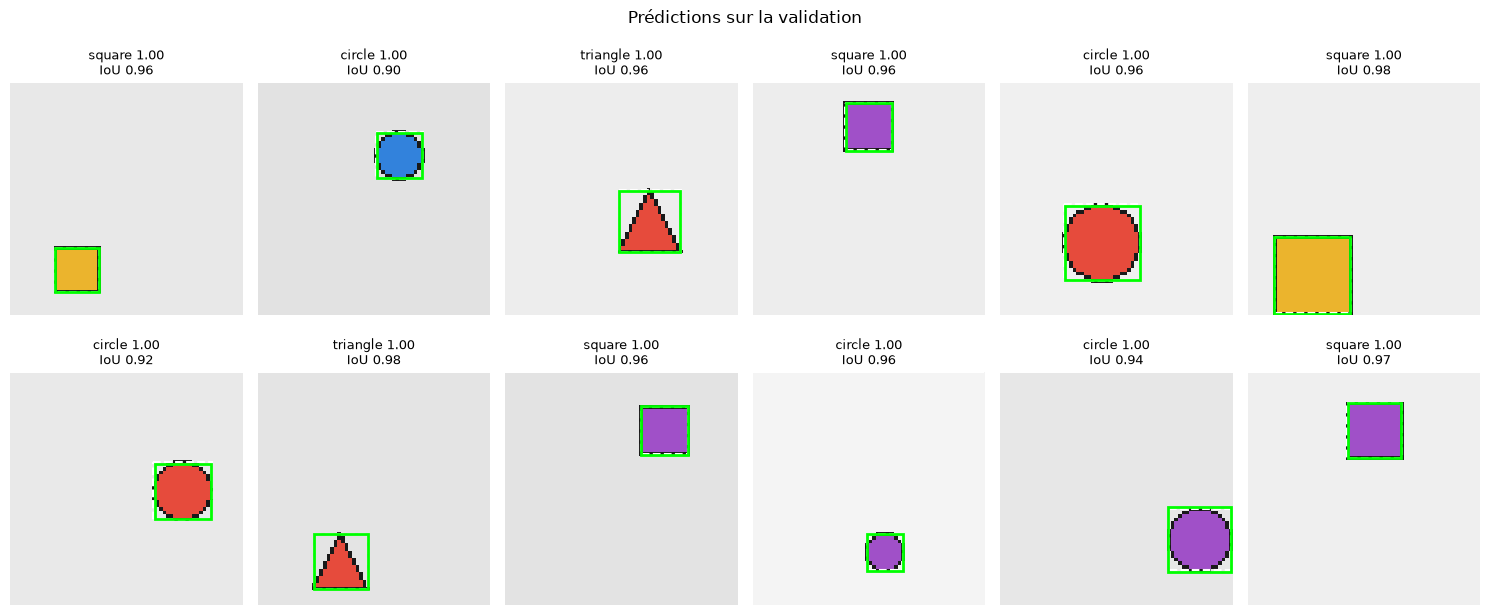

In [14]:
def show_predictions(model, dataset, indices, title, path=None, tag=None):  # dibuja las imágenes 'indices' con la caja predicha y la real
    model.eval()                                                   # modo evaluación
    fig, axes = plt.subplots(2, len(indices) // 2, figsize=(2.6 * len(indices) // 2, 6.6))  # 2 filas; la mitad de las imágenes en cada fila
    for ax, i in zip(axes.flat, indices):                          # axes.flat recorre las sub-gráficas una a una; i = número de imagen
        image, target = dataset[i]                                 # imagen (3, 64, 64) y objetivo (6, 8, 8)
        with torch.no_grad():                                      # sin gradientes
            logits = model(image[None])[0]                         # image[None] añade un eje: (3,64,64) -> (1,3,64,64) porque la red espera un lote; [0] quita ese eje de la salida
        box, score, class_id, class_prob = predict(logits, MODEL_SIZE)  # predict() de detector_multiclass.py: caja [x1,y1,x2,y2], confianza de objeto, clase y su probabilidad
        # Reconstruimos la caja real a partir del objetivo (el inverso de code())
        row, col = divmod(int(target[0].argmax()), GRID)           # celda con objeto (fila, columna)
        _, dx, dy, w, h, true_class = target[:, row, col].tolist() # sus 6 valores ("_" = el 1 de objectness, no lo necesitamos)
        tcx, tcy, tw, th = (col + dx) * STRIDE, (row + dy) * STRIDE, w * MODEL_SIZE, h * MODEL_SIZE  # centro y tamaño en píxeles
        truth = torch.tensor([tcx - tw / 2, tcy - th / 2, tcx + tw / 2, tcy + th / 2])  # centro/tamaño -> esquinas [x1, y1, x2, y2]
        good = class_id == int(true_class)                         # True si la forma predicha es la correcta
        ax.imshow(image.permute(1, 2, 0))                          # matplotlib quiere (alto, ancho, canales): (3,64,64) -> (64,64,3)
        x1, y1, x2, y2 = truth.tolist()                            # esquinas de la caja real
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="white", ls="--", lw=1.5))  # rectángulo: esquina, ancho, alto; blanco discontinuo
        x1, y1, x2, y2 = box.tolist()                              # esquinas de la caja predicha
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,  # rectángulo de la caja predicha (esquina, ancho, alto, sin relleno)...
                                   color="lime" if good else "red", lw=2))  # verde si la forma es correcta, rojo si no
        ax.set_title(f"{CLASSES[class_id]} {class_prob:.2f}\nIoU {float(iou(box, truth[None])[0]):.2f}", fontsize=9)  # forma + probabilidad, salto de línea (\n), IoU; iou() del TP espera (4,) y (N,4): truth[None] = (1,4)
        ax.axis("off")                                             # sin ejes
    fig.suptitle(title)                                            # título general
    fig.tight_layout()                                             # ajusta espacios
    if path is not None:                                           # si se dio una ruta...
        fig.savefig(path, dpi=150)                                 # ...se guarda la figura
    if tag is not None:                                            # si se dio un nombre para TensorBoard...
        writer.add_figure(tag, fig, close=False)                   # ...se envía a la pestaña IMAGES
    plt.show()                                                     # se muestra aquí

show_predictions(model, val_set, list(range(12)), "Prédictions sur la validation",  # las 12 primeras imágenes de validación
                 FIG_DIR / "predictions.png", tag="Evaluation/predictions")         # guardadas en disco y en TensorBoard

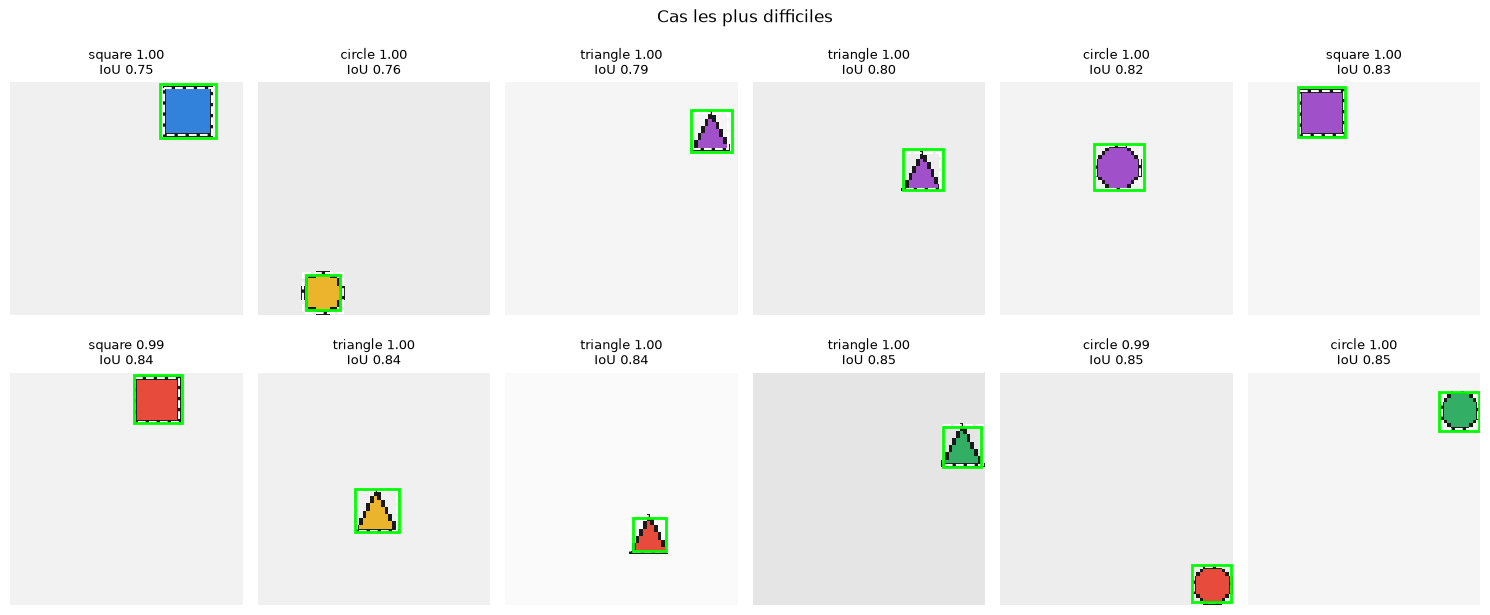

In [15]:
# Los casos más difíciles: primero los errores de forma, después los IoU más bajos
model.eval()                                                       # modo evaluación
with torch.no_grad():                                              # sin gradientes
    all_logits = model(val_set.tensors[0])                         # salidas para las 600 imágenes de una vez
errors = []                                                        # lista de tuplas (¿forma correcta?, IoU, número de imagen)
for i, (logits, target) in enumerate(zip(all_logits, val_set.tensors[1])):  # recorre salida y objetivo de cada imagen, con su número i
    _, _, class_id, _ = predict(logits, MODEL_SIZE)                # solo nos interesa la clase predicha (3er valor)
    true_class = int(target[5].flatten()[target[0].flatten().argmax()])  # clase real (canal 5 en la celda con objeto)
    errors.append((class_id == true_class, metrics["ious"][i].item(), i))  # .item(): tensor -> número
errors.sort()                                                      # ordena las tuplas: False < True (errores de forma primero), luego por IoU creciente
worst = [i for _, _, i in errors[:12]]                             # números de las 12 peores imágenes
show_predictions(model, val_set, worst, "Cas les plus difficiles", FIG_DIR / "erreurs.png", tag="Evaluation/pires_cas")  # las dibuja

### Ce que « voit » le réseau

À gauche, l'image ; à droite, 8 des 32 cartes produites par le backbone. Chaque carte s'allume
(couleur claire) là où elle repère quelque chose qui l'intéresse : un bord, un coin, une zone colorée…

> 🇪🇸 **Mapas de características.** `model.feature_maps()` aplica solo el backbone: salen 32 mapas de 8×8.
> Cada mapa es la respuesta de un "detector" aprendido: una celda clara significa que ese detector encontró
> lo que busca en esa zona. Normalmente se encienden alrededor de la figura y quedan apagados en el fondo.

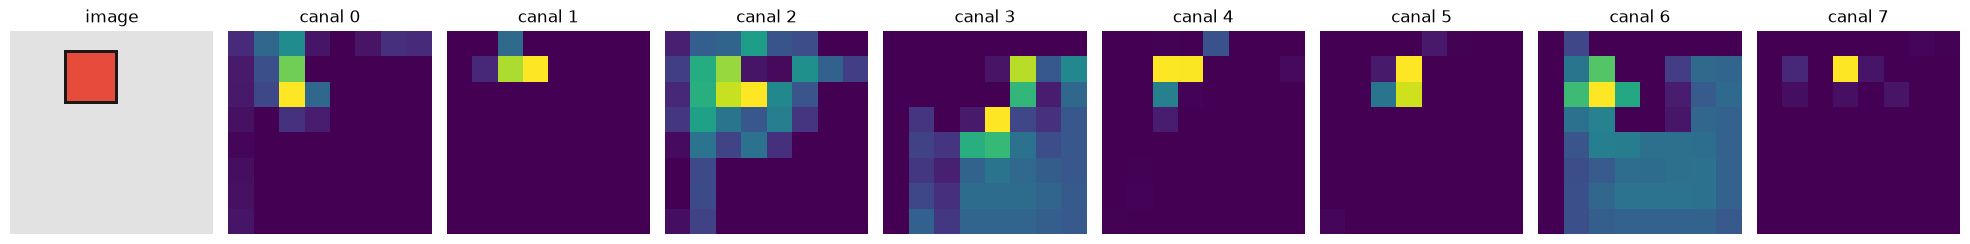

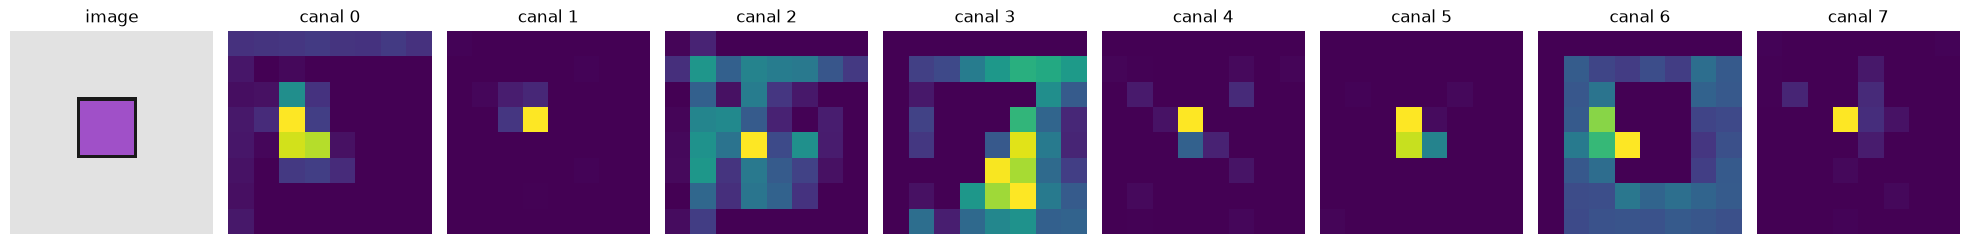

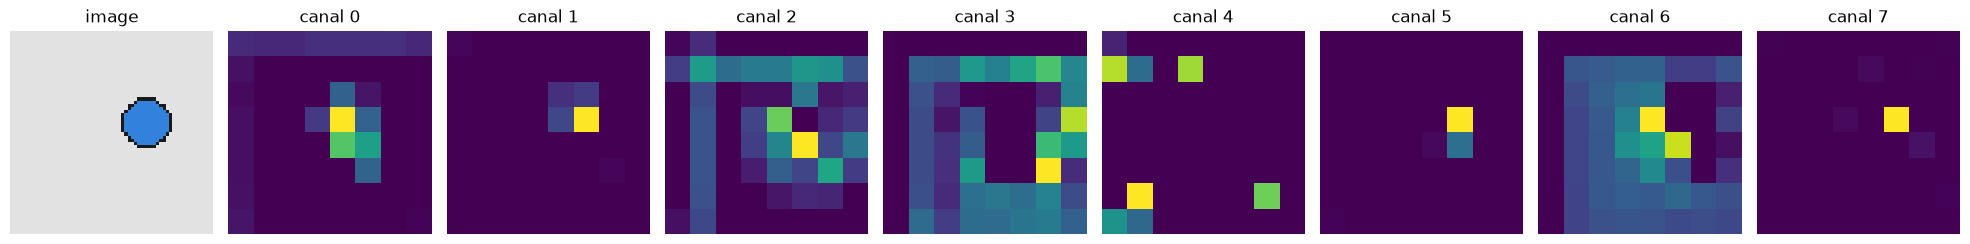

In [16]:
with torch.no_grad():                                             # sin gradientes
    maps = model.feature_maps(images_demo)                        # solo el backbone sobre las 10 imágenes de ejemplo -> (10, 32, 8, 8)
for i in range(3):                                                # para las 3 primeras imágenes...
    show_feature_maps(images_demo[i], maps[i], n_maps=8)          # ...visualize.py dibuja la imagen y sus 8 primeros mapas (de 32)

**Dans TensorBoard (onglet PROJECTOR).** Pour chaque image de validation, on prend les 32 valeurs du backbone
dans la case qui contient la figure : c'est le « résumé » de la figure à partir duquel la tête décide de la forme.
TensorBoard place ces 600 résumés dans un nuage de points en 3D (PCA ou t-SNE). Si on colore les points par `label`,
les trois formes forment des groupes bien séparés : c'est pour ça que la classification est si facile ici.

> 🇪🇸 **El PROJECTOR de TensorBoard**, explicado.
>
> Para cada imagen, la cabeza decide la forma a partir de **32 números**: los 32 valores de los mapas de características
> en la celda donde está la figura. Esos 32 números son como un "resumen" de la figura.
>
> El código los extrae: `feature_maps(...)` da `(600, 32, 8, 8)`; `.flatten(2)` lo pasa a `(600, 32, 64)` (las 64 celdas en fila);
> y `[idx, :, cell]` toma, para la imagen k, los 32 valores de **su** celda → `(600, 32)`.
>
> `add_embedding` los manda a TensorBoard con la forma real de cada uno (`metadata`) y su miniatura (`label_img`).
> En la pestaña **PROJECTOR** (menú desplegable arriba a la derecha si no aparece), TensorBoard reduce los 32 números
> a 3 (con PCA o t-SNE) para dibujarlos como puntos en 3D. Elige "Color by: label": si los puntos de cada forma
> quedan agrupados y separados, la cabeza solo tiene que "trazar fronteras" entre los grupos → clasificación fácil.

In [17]:
val_images, val_targets = val_set.tensors                          # (600, 3, 64, 64) y (600, 6, 8, 8)
idx = torch.arange(len(val_images))                                # [0, 1, 2, ..., 599]: un número por imagen
cell = val_targets[:, 0].flatten(1).argmax(dim=1)                  # para cada imagen: canal "¿objeto?" aplanado a 64 valores -> posición del 1 = número de celda (0..63)
with torch.no_grad():                                              # sin gradientes
    vectors = model.feature_maps(val_images).flatten(2)[idx, :, cell]   # mapas (600,32,8,8) -> (600,32,64); [idx, :, cell] = para la imagen k, los 32 valores de SU celda -> (600, 32)
labels = [CLASSES[int(c)] for c in val_targets[:, 5].flatten(1)[idx, cell]]  # forma real de cada imagen (canal 5 en su celda) como texto
writer.add_embedding(vectors, metadata=labels, label_img=val_images, tag="resume_de_la_figure")  # pestaña PROJECTOR: 600 puntos de 32 dimensiones, con su forma y su miniatura
writer.flush()                                                     # escribe en disco
print(vectors.shape, "-> onglet PROJECTOR")                        # (600, 32)

torch.Size([600, 32]) -> onglet PROJECTOR


## 8. Comparaison avec le modèle du TP

Pour savoir ce que nos changements apportent, on entraîne **sur les mêmes images et de la même façon** :
1. le **détecteur du TP** (`Detector`) : il ne connaît pas les formes, on ne regarde donc que la boîte ;
2. notre modèle **avec le petit backbone du TP** (`deep=False`) : pour voir l'effet du backbone plus profond ;
3. notre modèle **profond** (celui entraîné plus haut).

Chaque modèle a son propre dossier de logs : dans TensorBoard, leurs courbes se superposent
dans l'onglet SCALARS (cocher/décocher les runs à gauche), et l'onglet **HPARAMS** les résume dans un tableau.
Pour le détecteur du TP, la courbe « precision_classe » n'a pas de sens (il répond toujours « cercle ») : on l'ignore.

> 🇪🇸 **La comparación.** Para que sea justa, los tres modelos usan las mismas imágenes, la misma semilla, el mismo
> número de épocas y la misma función `fit()`.
>
> El problema es que el `Detector` del TP da 5 canales y `fit()`/`evaluate()` esperan 8. La clase `TPAsMultiClass`
> lo resuelve añadiendo 3 canales de ceros. Los ceros no dependen de ningún peso → el término de forma de la pérdida
> no cambia nada en la red, y el detector solo aprende la caja. (Su "precisión de forma" no tiene sentido: con 3 ceros,
> el softmax da 1/3 a cada forma y `max` devuelve en la práctica siempre la clase 0, "círculo".)
>
> Cada modelo escribe en su propio "run" de TensorBoard (`with SummaryWriter(...) as w:` lo cierra al terminar),
> así en **SCALARS** se pueden superponer sus curvas. `add_hparams` crea además una tabla en la pestaña **HPARAMS**.
>
> **Resultados de nuestra ejecución:**
>
> | modelo | IoU | IoU > 0.5 | forma | pesos |
> |---|---|---|---|---|
> | Detector del TP (solo caja) | 0.780 | 96.2 % | – | 6 309 |
> | Multiclase, backbone del TP | 0.782 | 96.2 % | 100 % | 6 408 |
> | Multiclase, backbone profundo | 0.948 | 100 % | 100 % | 35 736 |
>
> Cómo leerla: (1) con el mismo backbone, añadir la forma **no empeora** la caja (0.780 vs 0.782) y solo cuesta 99 pesos
> más (los de 3 canales extra en la cabeza: 3 × 32 + 3); (2) lo que mejora la caja es el **backbone más profundo** (0.78 → 0.95).

In [18]:
class TPAsMultiClass(torch.nn.Module):                                 # "envoltorio" para el Detector del TP
    # Le da al Detector del TP la misma salida que nuestros modelos (8 canales) añadiendo
    # 3 puntuaciones de forma a cero. No tienen pesos, así que no aprenden: solo se entrena la caja.
    # Gracias a esto podemos reutilizar fit(), train() y evaluate() sin cambiar nada.
    def __init__(self, detector):                                      # recibe un Detector del TP
        super().__init__()                                             # inicialización obligatoria de nn.Module
        self.detector = detector                                       # lo guarda (sus pesos pasan a ser parámetros del envoltorio)
    def forward(self, images):                                         # lo que pasa al hacer modelo(imágenes)
        out = self.detector(images)                                    # salida del TP: (B, 5, 8, 8)
        zeros = torch.zeros(out.shape[0], NUM_CLASSES, *out.shape[2:])  # tensor de ceros (B, 3, 8, 8); *out.shape[2:] = 8, 8
        return torch.cat([out, zeros], dim=1)                          # pega los dos en el eje de canales -> (B, 8, 8, 8)

torch.manual_seed(0)                                                   # misma semilla para cada modelo: comparación justa
tp_retrained = TPAsMultiClass(Detector())                              # detector del TP nuevo (sin entrenar) dentro del envoltorio
with SummaryWriter(log_dir=str(RUN_DIR / "detecteur_TP")) as w:        # su propio "run" de TensorBoard; "with" cierra el writer al terminar
    hist_tp = fit(tp_retrained, EPOCHS, w, verbose=False)              # mismo entrenamiento que el modelo principal, sin imprimir
torch.manual_seed(0)                                                   # misma semilla
light = MultiClassDetector(deep=False)                                 # nuestro modelo pero con el backbone pequeño del TP
with SummaryWriter(log_dir=str(RUN_DIR / "multiclasse_backbone_TP")) as w:  # otro "run"
    hist_light = fit(light, EPOCHS, w, verbose=False)                  # entrenamiento

results = {                                                            # nombre -> (métricas, red, ¿predice la forma?)
    "Détecteur du TP (boîte seule)": (evaluate(tp_retrained, val_loader, MODEL_SIZE), tp_retrained, False),  # evaluate() del detector del TP; False = no predice la forma
    "Multi-classes, backbone du TP": (evaluate(light, val_loader, MODEL_SIZE), light, True),  # evaluate() del modelo con backbone pequeño; True = sí predice la forma
    "Multi-classes, backbone profond": (metrics, model, True),         # el modelo principal ya estaba evaluado
}
print(f"{'modèle':34s} {'IoU':>6s} {'IoU>0.5':>8s} {'forme':>7s} {'params':>7s}")  # cabecera de la tabla (:>6s = alineado a la derecha en 6 caracteres)
for name, (m, net, has_class) in results.items():                     # recorre el diccionario: name = clave, (m, net, has_class) = valor desempaquetado
    params = sum(p.numel() for p in net.parameters())                  # número de pesos de esa red
    acc = f"{m['accuracy']:.1%}" if has_class else "-"                 # el TP no predice la forma: se pone "-"
    print(f"{name:34s} {m['mean_iou']:6.3f} {m['iou_gt_05']:8.1%} {acc:>7s} {params:7d}")  # una fila de la tabla
    # Pestaña HPARAMS: una fila por modelo, para compararlos en una tabla dentro de TensorBoard
    with SummaryWriter(log_dir=str(RUN_DIR / "hparams")) as w:         # carpeta común para la tabla
        w.add_hparams({"modele": name, "parametres": params},          # columnas de "configuración"
                      {"hparam/IoU_moyen": m["mean_iou"], "hparam/IoU_gt_0.5": m["iou_gt_05"]},  # columnas de resultados
                      run_name=name)                                   # nombre de la fila

C:\Users\lucas\Downloads\ISIS\NNR\rnn\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
C:\Users\lucas\Downloads\ISIS\NNR\rnn\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


modèle                                IoU  IoU>0.5   forme  params
Détecteur du TP (boîte seule)       0.780    96.2%       -    6309
Multi-classes, backbone du TP       0.782    96.2%  100.0%    6408
Multi-classes, backbone profond     0.948   100.0%  100.0%   35736


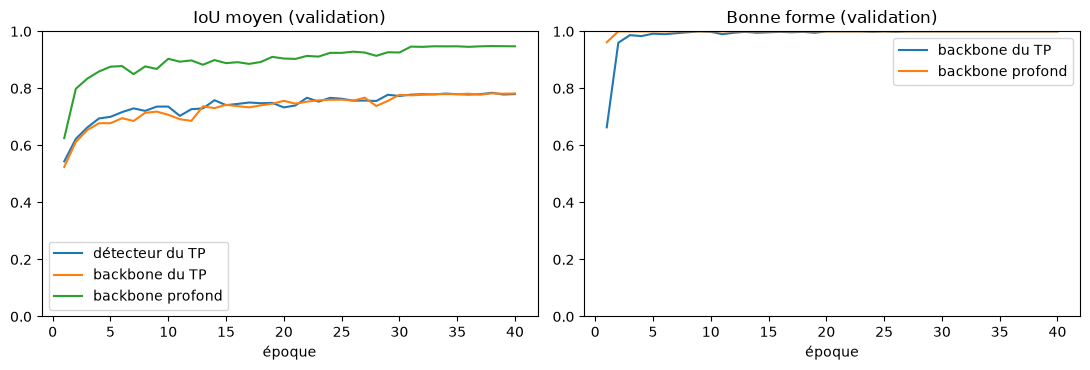

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))                  # 2 gráficas lado a lado
epochs = range(1, EPOCHS + 1)                                      # eje x: épocas 1..40
for name, h in (("détecteur du TP", hist_tp), ("backbone du TP", hist_light), ("backbone profond", history)):  # los 3 historiales
    axes[0].plot(epochs, h["mean_iou"], label=name)               # izquierda: IoU medio por época
    if h is not hist_tp:                                           # el TP no predice la forma ("is not" = no es el mismo objeto)
        axes[1].plot(epochs, h["accuracy"], label=name)           # derecha: % de formas acertadas
axes[0].set_title("IoU moyen (validation)")                        # título izquierda
axes[1].set_title("Bonne forme (validation)")                      # título derecha
for ax in axes:                                                    # para las dos gráficas:
    ax.set_xlabel("époque")                                        # nombre del eje x
    ax.set_ylim(0, 1)                                              # eje y de 0 a 1
    ax.legend()                                                    # leyenda con los nombres
fig.tight_layout()                                                 # ajusta espacios
fig.savefig(FIG_DIR / "comparaison.png", dpi=150)                  # guarda para el informe
writer.add_figure("Comparaison/courbes", fig, close=False)         # envía a TensorBoard
plt.show()                                                         # muestra aquí

## 9. Sauvegarde

> 🇪🇸 `torch.save(model.state_dict(), ...)` guarda solo los pesos. Para reutilizar el modelo más tarde:
> ```python
> model = MultiClassDetector()                                     # misma arquitectura
> model.load_state_dict(torch.load("detector_multiclass.pt"))     # se cargan los pesos aprendidos
> model.eval()                                                     # modo evaluación
> ```
> `writer.close()` cierra el diario de TensorBoard del modelo principal.

In [20]:
torch.save(model.state_dict(), "detector_multiclass.pt")   # state_dict() = diccionario {nombre de capa: tensor de pesos}; se guarda en un archivo .pt
writer.close()                                              # cierra el diario de TensorBoard (escribe lo pendiente)
print("modèle sauvegardé dans detector_multiclass.pt")      # mensaje de confirmación

modèle sauvegardé dans detector_multiclass.pt


## 10. Ce qu'il faut retenir

* **Ajouter la forme coûte peu** : 3 sorties de plus dans la tête, une valeur de plus dans la cible,
  un terme de plus dans la perte. La partie « boîte » ne change pas du tout.
* **Reconnaître la forme est facile ici** : comme la couleur est aléatoire, le réseau apprend bien la forme,
  et même le petit backbone du TP trouve la bonne forme presque à chaque fois
  (le PROJECTOR de TensorBoard le montre bien : les trois formes forment des groupes séparés).
* **Ce qui fait la différence, c'est la précision de la boîte** : le backbone plus profond améliore nettement l'IoU.
* **Apprendre la forme en plus ne gêne pas la boîte** : à backbone égal, on localise aussi bien que le détecteur du TP.
* **Limites** : une seule figure par image (la NMS ne sert presque à rien), figures toujours aussi larges que hautes,
  pas de rotation, fond uni sans bruit. Les très bons scores viennent en partie de ces images très simples ;
  on ne les retrouverait pas sur de vraies photos. Les erreurs de boîte qui restent concernent surtout les petites figures.
* **Pour aller plus loin** : plusieurs figures par image (option C), ancres (option A), ajouter du bruit
  ou des rotations aux images, régler le poids du terme de forme.

> 🇪🇸 **Mini-glosario para la presentación**
>
> | término | en pocas palabras |
> |---|---|
> | tensor | array de números de varias dimensiones (una imagen = `(3, 64, 64)`) |
> | backbone | la parte de la red que extrae "características" de la imagen (aquí: convoluciones) |
> | feature maps | lo que sale del backbone: 32 mapas de 8×8 |
> | cabeza (head) | la última capa, que convierte las características en la respuesta (caja + forma) |
> | stride | cuántos píxeles avanza el filtro; aquí la imagen se reduce 8 veces en total |
> | celda responsable | la celda de la cuadrícula 8×8 que contiene el centro de la figura |
> | logit | salida "en bruto" de la red, antes de sigmoide/softmax |
> | sigmoide | lleva un número a [0, 1] (para "¿objeto?", dx, dy, w, h) |
> | softmax | convierte 3 números en 3 probabilidades que suman 1 (para la forma) |
> | IoU | intersección / unión de dos cajas: 1 = idénticas, 0 = separadas |
> | NMS | entre cajas que se solapan, quedarse con la de mayor puntuación |
> | época | una pasada por todas las imágenes de entrenamiento |
> | lote (batch) | grupo de imágenes procesadas a la vez (64) |
> | lr | tamaño del paso con el que se corrigen los pesos |
> | validación | imágenes que la red nunca ve al aprender, para medir si generaliza |
> | matriz de confusión | tabla real × predicha; la diagonal son los aciertos |